# 08 — Demand Profiles and Two-Stage Stochastic Optimization

Split from `WindForecasting.ipynb`. Contents: construction of the deterministic and representative demand profiles from the operational dataset (optimization inputs), an optional runner for the Gurobi optimization pipeline scripts (`run_100_scenarios.py`, `compute_vss_evpi.py`, `evaluate_out_of_sample.py`, `decision_value_analysis.py`, …), and viewers for the key results: SAA solution, VSS/EVPI, out-of-sample validation, RP-vs-EEV comparison, VSS decomposition, and the deterministic-plan ablation.

**Prerequisite:** wind-power scenario files from `07_Scenario_Generation.ipynb` must exist in `data/optimization_input/`.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from rich.jupyter import display

# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

# Walk upward until a folder containing the raw wind dataset is found,
# so this notebook works from Data/Microgrid-Forecasting-Stochastic-
# Optimization/notebooks as well as from Data/notebooks. If the raw
# data is later copied into this repository's data/raw, the repository
# root is used automatically.
_candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
PROJECT_ROOT = None
for candidate in _candidates:
    if (candidate / "data" / "raw" / "agregatenew.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    # GitHub clone: raw data absent, derived inputs distributed
    for candidate in _candidates:
        if (candidate / "data" / "optimization_input"
                / "pgu_parameters.csv").exists():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OPT_INPUT_DIR = PROJECT_ROOT / "data" / "optimization_input"
OPT_OUTPUT_DIR = PROJECT_ROOT / "data" / "optimization_output"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")

Project root: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data
Raw data: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/raw


In [150]:
import os

print(os.getcwd())

/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/notebooks


In [151]:
operational_df = pd.read_csv(OPERATIONAL_FILE)


print("Operational dataset:", operational_df.shape)
display(operational_df.head())

Operational dataset: (3546, 10)


,timestamp,grid_load_demand,frequency,voltage,power_exchange,battery_state_of_charge,battery_charging_rate,battery_discharging_rate,hour_of_day,day_of_week
0,1/1/23 0:00,294.401249,49.123760,228.933029,-30.551108,10.385097,45.365558,36.183096,0,6
1,1/1/23 1:00,185.824084,49.908870,223.617160,-2.023332,86.303649,7.791319,7.240728,1,6
2,1/1/23 2:00,347.363574,49.575119,222.854681,94.963947,92.269351,41.131011,21.848508,2,6
3,1/1/23 3:00,193.641771,49.549129,227.861872,52.712924,48.242636,35.145735,14.418611,3,6
4,1/1/23 4:00,244.023572,49.444763,221.981539,70.347948,42.547153,48.760586,49.343433,4,6


In [153]:
# ============================================================
# CREATE 24-HOUR DETERMINISTIC DEMAND PROFILE
# ============================================================

# Ensure timestamp is datetime before extracting hour
operational_df["timestamp"] = pd.to_datetime(
    operational_df["timestamp"],
    errors="coerce"
)

if operational_df["timestamp"].isna().any():
    raise ValueError(
        "Some timestamps could not be parsed."
    )

# Extract hour from timestamp
operational_df["hour"] = operational_df["timestamp"].dt.hour

# Calculate hourly demand statistics
demand_profile = (
    operational_df
    .groupby("hour")["grid_load_demand"]
    .agg(
        demand_kw="mean",
        demand_std_kw="std",
        demand_min_kw="min",
        demand_max_kw="max"
    )
    .reset_index()
)

# Convert hours 0–23 to optimization hours 1–24
demand_profile["hour"] = demand_profile["hour"] + 1

# Define output file using centralized project path
DEMAND_PROFILE_FILE = OPT_INPUT_DIR / "demand_profile.csv"

# Save
demand_profile.to_csv(
    DEMAND_PROFILE_FILE,
    index=False
)

# Verify
print("=" * 60)
print("DEMAND PROFILE CREATED")
print("=" * 60)
print(f"Shape: {demand_profile.shape}")
print(f"Saved to: {DEMAND_PROFILE_FILE}")
print(f"File exists: {DEMAND_PROFILE_FILE.exists()}")
print()

display(demand_profile.round(3))


DEMAND PROFILE CREATED
Shape: (24, 5)
Saved to: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_input/demand_profile.csv
File exists: True



/var/folders/yt/mlb3t9fs72z0t7xtn71_d6c00000gn/T/ipykernel_39152/1332709903.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  operational_df["timestamp"] = pd.to_datetime(


,hour,demand_kw,demand_std_kw,demand_min_kw,demand_max_kw
0,1,276.550,128.432,53.302,499.735
1,2,265.580,132.535,50.110,499.092
2,3,275.647,133.683,51.462,495.093
3,4,276.065,126.076,56.019,496.929
4,5,261.518,128.409,60.618,490.873
5,6,269.922,131.164,53.273,498.907
6,7,266.151,128.942,52.016,499.863
7,8,260.324,130.315,50.088,498.794
8,9,269.067,140.026,56.606,497.575
9,10,255.265,134.747,50.653,490.192


### Create representative demand profiles

In [154]:
# ============================================================
# REPRESENTATIVE 24-HOUR DEMAND PROFILES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure timestamp is datetime
operational_df["timestamp"] = pd.to_datetime(
    operational_df["timestamp"],
    errors="coerce"
)

if operational_df["timestamp"].isna().any():
    raise ValueError(
        "Some timestamps could not be parsed."
    )

# Create date and hour fields
operational_df["date"] = (
    operational_df["timestamp"].dt.date
)

operational_df["hour_zero_based"] = (
    operational_df["timestamp"].dt.hour
)

# Confirm that each date-hour pair is unique
duplicate_date_hours = operational_df.duplicated(
    subset=["date", "hour_zero_based"]
).sum()

print(
    "Duplicate date-hour observations:",
    duplicate_date_hours
)

if duplicate_date_hours > 0:
    raise ValueError(
        "Duplicate hourly observations exist. "
        "Aggregate or inspect them before continuing."
    )


# ============================================================
# CONSTRUCT DAILY 24-HOUR TRAJECTORIES
# ============================================================

daily_demand = operational_df.pivot(
    index="date",
    columns="hour_zero_based",
    values="grid_load_demand"
)

# Retain only complete 24-hour days
daily_demand = daily_demand.dropna()

# Ensure proper hour ordering
daily_demand = daily_demand.reindex(
    columns=range(24)
)

print(
    "Complete 24-hour days:",
    len(daily_demand)
)

print(
    "Daily demand matrix shape:",
    daily_demand.shape
)

if daily_demand.shape[1] != 24:
    raise ValueError(
        "Daily profiles do not contain exactly 24 hours."
    )

Duplicate date-hour observations: 0
Complete 24-hour days: 147
Daily demand matrix shape: (147, 24)


In [155]:
# ============================================================
# DAILY DEMAND CHARACTERISTICS
# ============================================================

daily_summary = pd.DataFrame({

    "mean_demand_kw":
        daily_demand.mean(axis=1),

    "minimum_demand_kw":
        daily_demand.min(axis=1),

    "peak_demand_kw":
        daily_demand.max(axis=1),

    "std_demand_kw":
        daily_demand.std(axis=1),

    "daily_energy_kwh":
        daily_demand.sum(axis=1),

    "peak_to_average_ratio":
        daily_demand.max(axis=1)
        /
        daily_demand.mean(axis=1)

})

display(
    daily_summary.describe().round(3)
)

,mean_demand_kw,minimum_demand_kw,peak_demand_kw,std_demand_kw,daily_energy_kwh,peak_to_average_ratio
count,147.000,147.000,147.000,147.000,147.000,147.000
mean,271.069,66.164,480.495,128.665,6505.653,1.786
std,24.820,15.155,18.833,11.934,595.668,0.162
min,199.951,50.050,411.608,92.841,4798.827,1.455
25%,257.801,55.376,473.169,122.527,6187.222,1.695
50%,270.840,62.090,486.997,128.084,6500.156,1.771
75%,284.433,72.454,493.874,135.271,6826.387,1.855
max,342.285,136.933,499.863,158.175,8214.849,2.468


In [156]:
# ============================================================
# SELECT REPRESENTATIVE OBSERVED DAYS
# ============================================================

energy_series = daily_summary[
    "daily_energy_kwh"
]

median_energy = energy_series.median()


low_demand_date = (
    energy_series.idxmin()
)

high_demand_date = (
    energy_series.idxmax()
)

median_demand_date = (
    energy_series
    .sub(median_energy)
    .abs()
    .idxmin()
)

high_variability_date = (
    daily_summary[
        "std_demand_kw"
    ]
    .idxmax()
)


representative_dates = {

    "low_demand":
        low_demand_date,

    "median_demand":
        median_demand_date,

    "high_demand":
        high_demand_date,

    "high_variability":
        high_variability_date

}


print("Representative dates")

for profile, date in representative_dates.items():
    print(f"{profile}: {date}")

Representative dates
low_demand: 2023-05-22
median_demand: 2023-02-09
high_demand: 2023-04-06
high_variability: 2023-04-14


In [157]:
# ============================================================
# EXPORT REPRESENTATIVE PROFILES
# ============================================================

representative_profiles = []

for profile_name, profile_date in representative_dates.items():

    values = daily_demand.loc[
        profile_date
    ].to_numpy(dtype=float)

    profile_df = pd.DataFrame({

        "profile":
            profile_name,

        "source_date":
            str(profile_date),

        "hour":
            np.arange(1, 25),

        "demand_kw":
            values

    })

    representative_profiles.append(
        profile_df
    )


representative_demand_df = pd.concat(
    representative_profiles,
    ignore_index=True
)


REPRESENTATIVE_FILE = (
    OPT_INPUT_DIR
    / "representative_demand_profiles.csv"
)

representative_demand_df.to_csv(
    REPRESENTATIVE_FILE,
    index=False
)


print(
    "Saved representative profiles to:"
)

print(REPRESENTATIVE_FILE)

display(
    representative_demand_df.head(30)
)

Saved representative profiles to:
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_input/representative_demand_profiles.csv


,profile,source_date,hour,demand_kw
0,low_demand,2023-05-22,1,169.537400
1,low_demand,2023-05-22,2,54.854823
2,low_demand,2023-05-22,3,119.674093
3,low_demand,2023-05-22,4,493.557306
4,low_demand,2023-05-22,5,193.910561
5,low_demand,2023-05-22,6,98.970756
6,low_demand,2023-05-22,7,103.441462
7,low_demand,2023-05-22,8,189.654221
8,low_demand,2023-05-22,9,66.940269
9,low_demand,2023-05-22,10,280.169865


In [158]:
# ============================================================
# BASE-MODEL DEMAND PROFILE
# ============================================================

base_demand_profile = (
    representative_demand_df[
        representative_demand_df["profile"]
        ==
        "median_demand"
    ][
        [
            "hour",
            "demand_kw"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


BASE_DEMAND_FILE = (
    OPT_INPUT_DIR
    / "demand_profile.csv"
)


base_demand_profile.to_csv(
    BASE_DEMAND_FILE,
    index=False
)


print("Base demand profile:")
print(BASE_DEMAND_FILE)

display(
    base_demand_profile.round(3)
)

Base demand profile:
/Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/optimization_input/demand_profile.csv


,hour,demand_kw
0,1,216.615
1,2,135.710
2,3,417.440
3,4,321.459
4,5,212.187
5,6,249.726
6,7,421.944
7,8,202.517
8,9,90.335
9,10,460.077


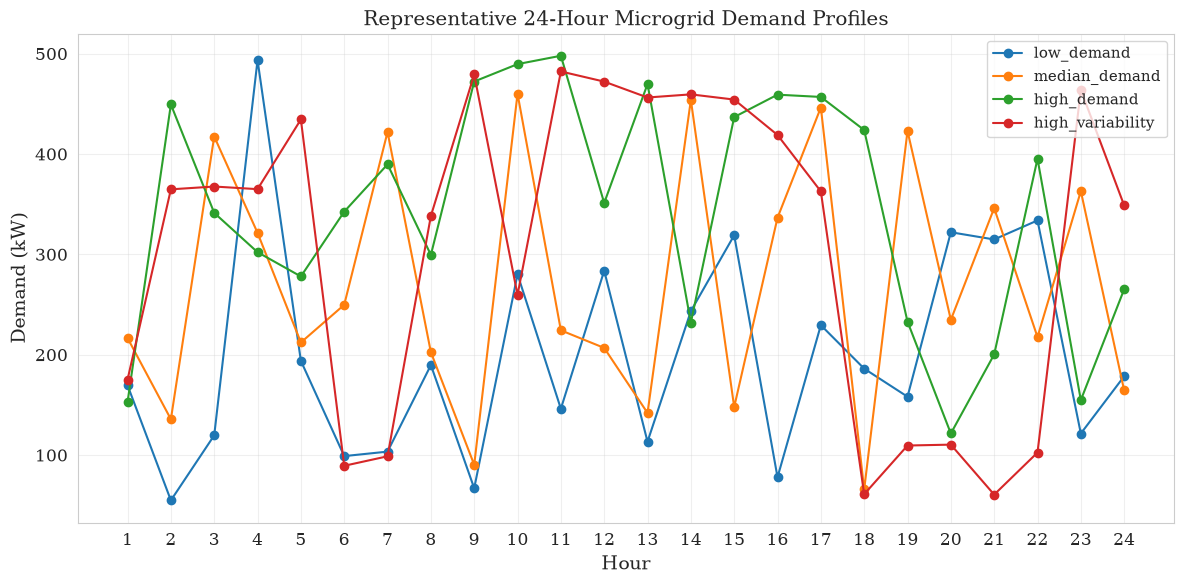

In [159]:
# ============================================================
# VISUALIZE REPRESENTATIVE DEMAND PROFILES
# ============================================================

plt.figure(figsize=(12, 6))

for profile_name in (
    representative_demand_df["profile"].unique()
):

    profile_data = representative_demand_df[
        representative_demand_df["profile"]
        ==
        profile_name
    ]

    plt.plot(
        profile_data["hour"],
        profile_data["demand_kw"],
        marker="o",
        label=profile_name
    )


plt.title(
    "Representative 24-Hour Microgrid Demand Profiles"
)

plt.xlabel("Hour")
plt.ylabel("Demand (kW)")

plt.xticks(range(1, 25))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Run the optimization pipeline (optional)

In [ ]:
# ============================================================
# RUN THE TWO-STAGE STOCHASTIC OPTIMIZATION PIPELINE
#
# The optimization lives in the project-level scripts (Gurobi).
# Set RUN_PIPELINE = True to re-run everything; leave False to
# only inspect the previously generated outputs below.
# ============================================================

import subprocess
import sys

RUN_PIPELINE = False

PIPELINE_SCRIPTS = [
    "run_base_model.py",
    "run_scenario_comparison.py",
    "run_100_scenarios.py",
    "validate_scenario_reduction.py",
    "validate_100_solution.py",
    "compute_vss_evpi.py",
    "analyze_eev_performance.py",
    "evaluate_out_of_sample.py",
    "create_publication_results.py",
    "decision_value_analysis.py",
]

if RUN_PIPELINE:
    for script in PIPELINE_SCRIPTS:
        print("=" * 60)
        print("Running", script)
        result = subprocess.run(
            [sys.executable, script],
            cwd=PROJECT_ROOT,
            capture_output=True,
            text=True,
        )
        print(result.stdout[-3000:])
        if result.returncode != 0:
            print(result.stderr[-3000:])
            raise RuntimeError(f"{script} failed")
else:
    print("RUN_PIPELINE is False; inspecting existing outputs.")

## Inspect results

In [ ]:
# ============================================================
# INSPECT KEY OPTIMIZATION RESULTS
# ============================================================

from IPython.display import display

result_files = {
    "Scenario-count comparison":
        OPT_OUTPUT_DIR / "scenario_count_comparison.csv",
    "100-scenario solution summary":
        OPT_OUTPUT_DIR / "scenarios_100" / "solution_summary.csv",
    "VSS / EVPI":
        OPT_OUTPUT_DIR / "vss_evpi_analysis" / "vss_evpi_summary.csv",
    "Out-of-sample (1,000 scenarios)":
        OPT_OUTPUT_DIR / "out_of_sample_1000" / "out_of_sample_summary.csv",
    "RP vs EEV summary":
        OPT_OUTPUT_DIR / "publication_results" / "rp_vs_eev_summary_table.csv",
    "VSS decomposition":
        OPT_OUTPUT_DIR / "decision_analysis" / "vss_decomposition.csv",
    "Ablation (A0/A1/EV)":
        OPT_OUTPUT_DIR / "decision_analysis" / "ablation_results.csv",
}

for title, path in result_files.items():
    print("=" * 60)
    print(title)
    if path.exists():
        display(pd.read_csv(path))
    else:
        print("  (not generated yet:", path.name + ")")